### This comprehensive Python program integrates realistic well logs with seismic attributes to perform seismic facies analysis for Sabah's deepwater turbidite reservoirs. 
#### Here's what it does:

#### Generates synthetic seismic data simulating turbidite channels and surrounding shale

### Calculates key seismic attributes:

RMS Amplitude

Acoustic Impedance

Entropy (texture analysis)

Spectral Decomposition

Reflector Continuity

### Generates realistic well logs for Sabah:

Gamma Ray (GR) - low in sand, high in shale

Resistivity (RT) - high in hydrocarbon-bearing sand

Porosity (PHI) - higher in sand

Facies classification based on log responses

Performs seismic facies analysis using K-means clustering to distinguish:

Shale (blue)

Sand (yellow)

Hydrocarbon sand (red)

### Visualizes the results with:

Seismic section and attribute maps

Well locations on facies classification

Detailed well log displays

The program demonstrates how different turbidite units exhibit distinct amplitude and continuity characteristics, helping to distinguish them from surrounding marine shale. The high acoustic impedance contrast between sand and shale layers results in a strong amplitude response, which is captured by the seismic attributes.

This approach can help geoscientists identify and characterize turbidite reservoirs in the Sabah oil fields, supporting exploration and development decisions.


#### Keith R. Holdaway FGS

Generating synthetic seismic data for Sabah turbidite reservoirs...
Calculating RMS Amplitude...
Calculating Acoustic Impedance...
Calculating Entropy...
Calculating Spectral Decomposition at 30 Hz...
Calculating Reflector Continuity...
Generating realistic well logs for Sabah...
Generated logs for Well_1 at position (37, 50)
Generated logs for Well_2 at position (75, 100)
Generated logs for Well_3 at position (112, 150)
Performing seismic facies analysis...
Visualizing facies analysis at time slice 50...


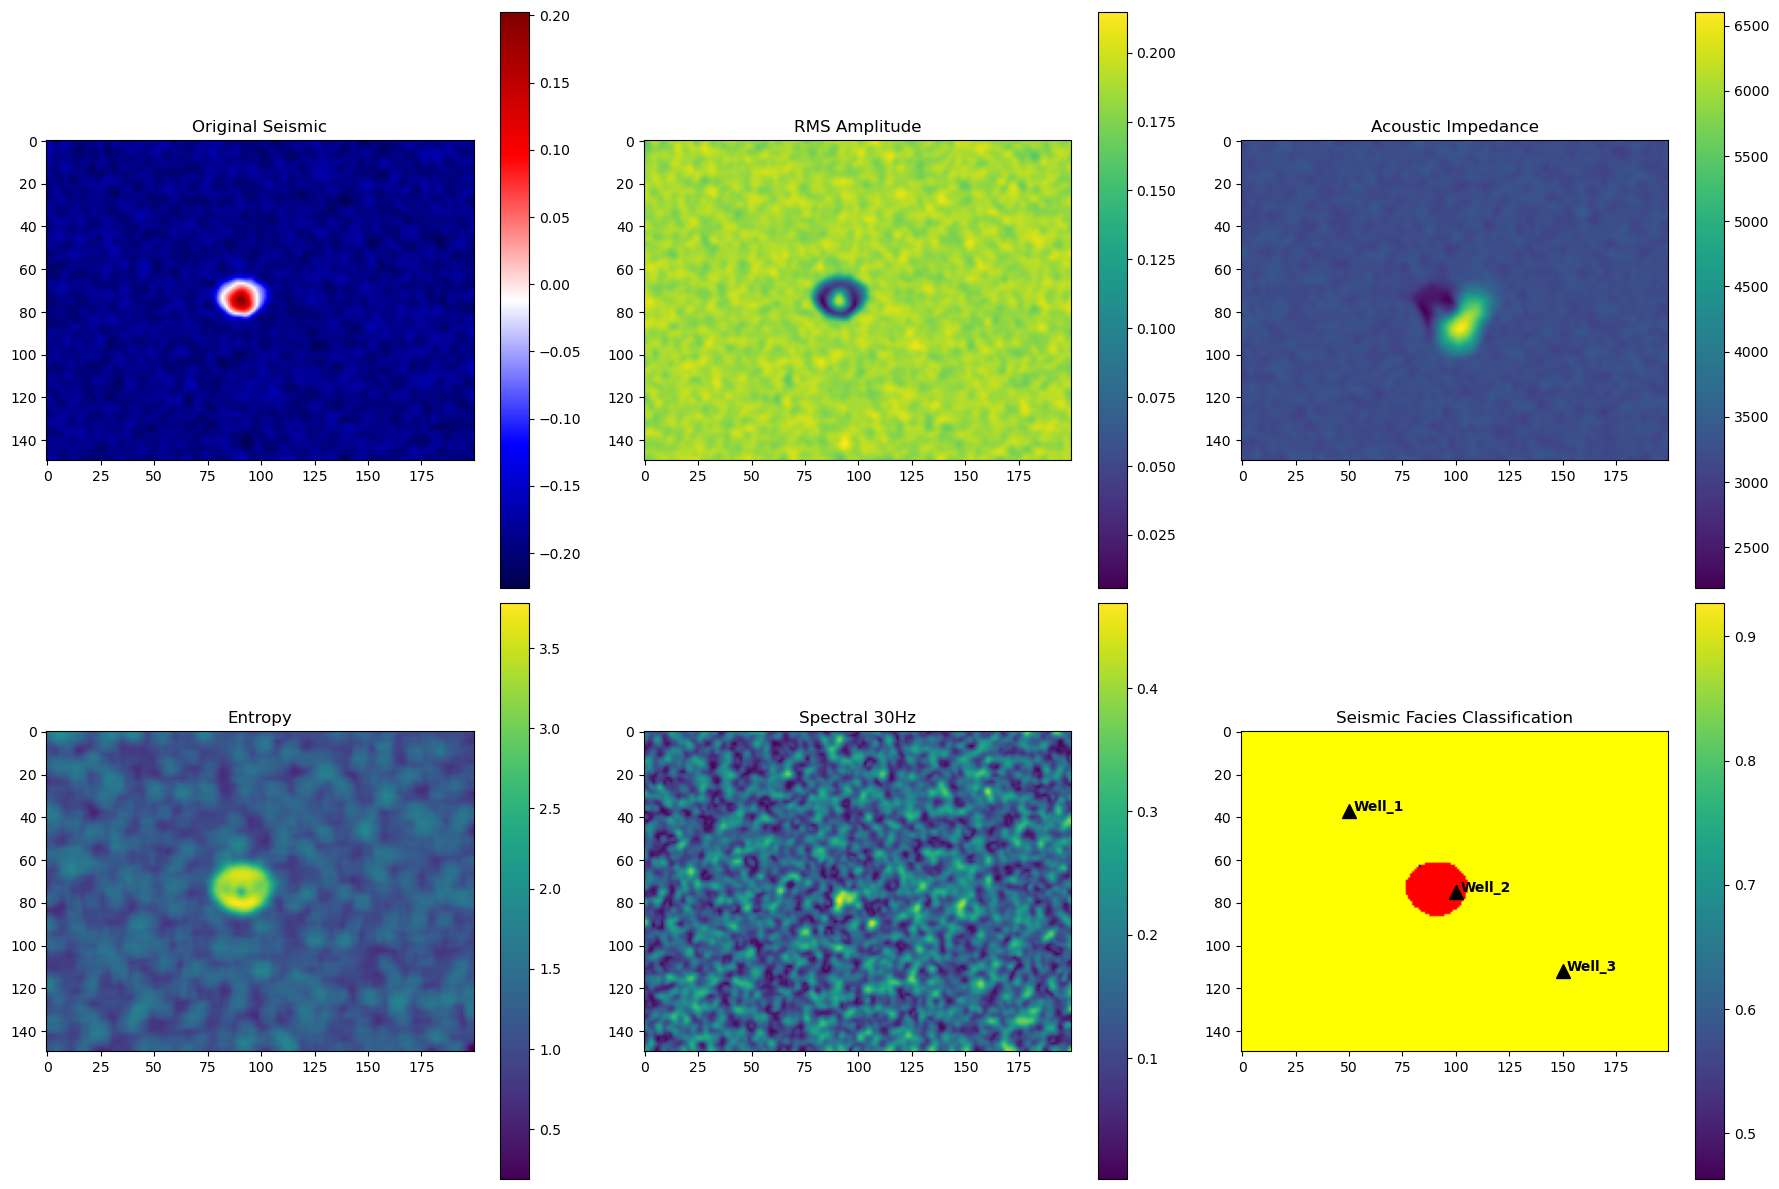

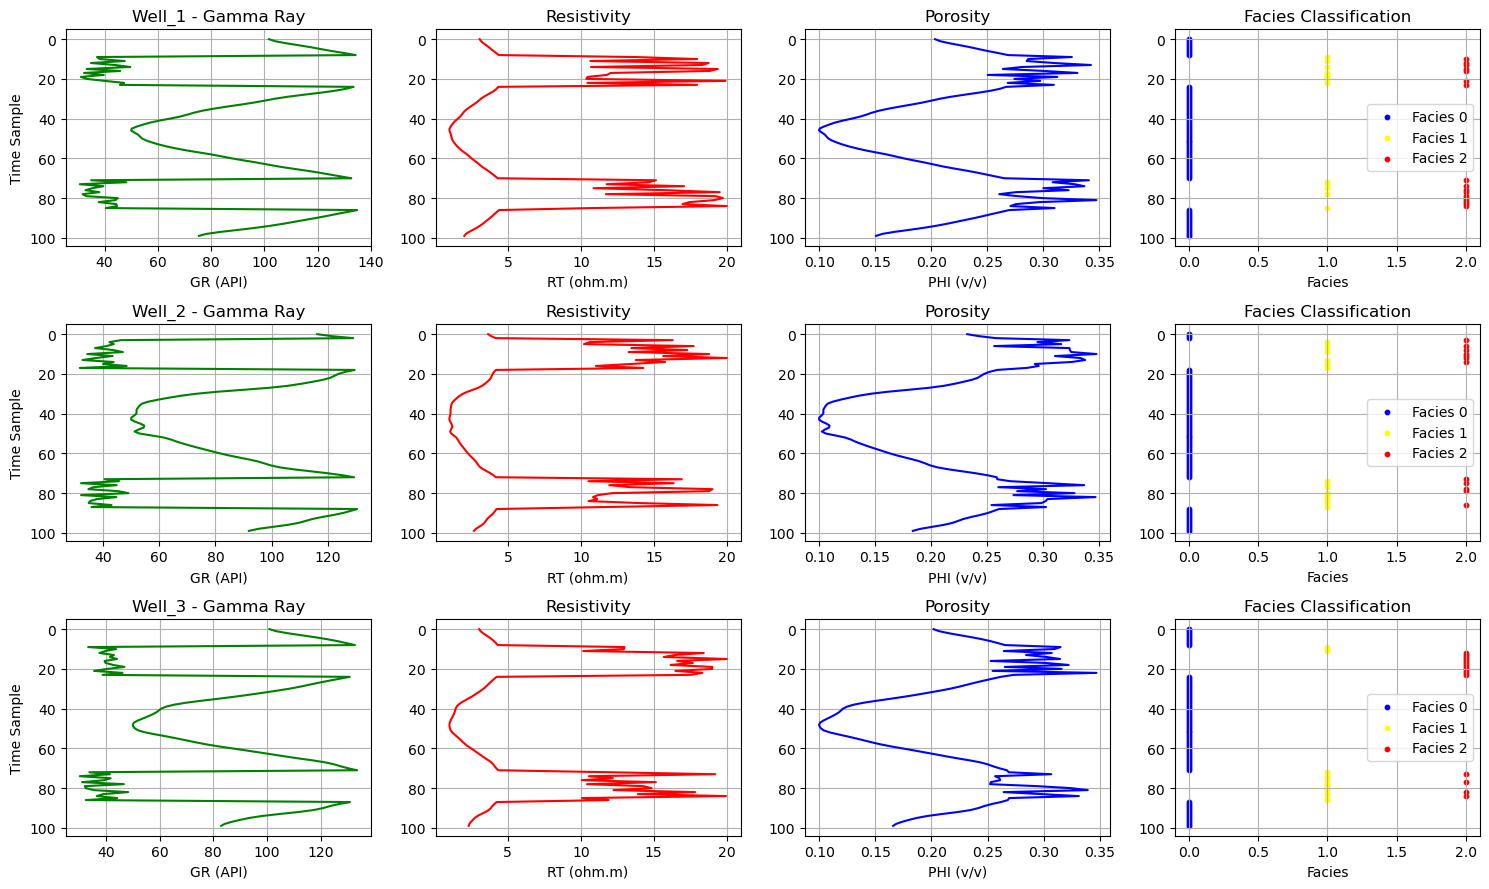

Seismic facies analysis complete. Turbidite channels should be visible in the facies classification.


In [1]:
# Seismic Facies Analysis with Well Log Display for Sabah Turbidite Reservoirs

import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage
from scipy.fft import fftfreq
import numpy.fft as fft
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.colors as mcolors

# Set random seed for reproducibility
np.random.seed(42)

class SeismicFaciesAnalysis:
    def __init__(self, seismic_data):
        """
        Initialize with 3D seismic data
        
        Parameters:
        seismic_data (numpy.ndarray): 3D array of seismic data with dimensions [time, xline, iline]
        """
        self.data = seismic_data
        self.nt, self.nx, self.ny = seismic_data.shape
        self.attributes = {}
        
    def calculate_rms_amplitude(self, window_size=5):
        """Calculate RMS amplitude attribute"""
        print("Calculating RMS Amplitude...")
        rms_volume = np.zeros_like(self.data)
        
        padded_data = np.pad(self.data, ((window_size//2, window_size//2), 
                                         (0, 0), (0, 0)), mode='reflect')
        
        for i in range(self.nt):
            start = i
            end = i + window_size
            window = padded_data[start:end, :, :]
            rms_volume[i, :, :] = np.sqrt(np.mean(window**2, axis=0))
            
        self.attributes['RMS Amplitude'] = rms_volume
        return rms_volume
    
    def calculate_acoustic_impedance(self):
        """Simulate acoustic impedance inversion"""
        print("Calculating Acoustic Impedance...")
        
        impedance = np.cumsum(np.abs(self.data), axis=0)
        impedance = impedance / np.max(impedance) * 10000
        
        impedance += 500 * np.sin(np.linspace(0, 4*np.pi, self.nt))[:, None, None]
        
        self.attributes['Acoustic Impedance'] = impedance
        return impedance
    
    def calculate_entropy(self, window_size=7):
        """Calculate entropy for texture analysis"""
        print("Calculating Entropy...")
        entropy_volume = np.zeros_like(self.data)
        
        normalized_data = (self.data - np.min(self.data)) / (np.max(self.data) - np.min(self.data))
        
        pad_size = window_size // 2
        padded_data = np.pad(normalized_data, ((pad_size, pad_size), 
                                              (pad_size, pad_size), 
                                              (pad_size, pad_size)), mode='reflect')
        
        for i in range(self.nt):
            for j in range(self.nx):
                for k in range(self.ny):
                    window = padded_data[i:i+window_size, j:j+window_size, k:k+window_size]
                    hist, _ = np.histogram(window, bins=32, range=(0, 1))
                    prob = hist / np.sum(hist)
                    entropy = -np.sum(prob * np.log2(prob + (prob == 0)))
                    entropy_volume[i, j, k] = entropy
        
        self.attributes['Entropy'] = entropy_volume
        return entropy_volume
    
    def calculate_spectral_decomposition(self, frequency):
        """Perform spectral decomposition at a specific frequency"""
        print(f"Calculating Spectral Decomposition at {frequency} Hz...")
        
        fft_data = fft.fft(self.data, axis=0)
        sample_rate = 4.0  # ms
        freq_bins = fft.fftfreq(self.nt, d=sample_rate/1000)
        target_bin = np.argmin(np.abs(freq_bins - frequency))
        
        spectral_magnitude = np.abs(fft_data[target_bin, :, :])
        spectral_volume = np.repeat(spectral_magnitude[np.newaxis, :, :], self.nt, axis=0)
        
        self.attributes[f'Spectral {frequency}Hz'] = spectral_volume
        return spectral_volume
    
    def calculate_reflector_continuity(self, window_size=9):
        """Calculate reflector continuity attribute"""
        print("Calculating Reflector Continuity...")
        
        grad_x = ndimage.sobel(self.data, axis=1)
        grad_y = ndimage.sobel(self.data, axis=2)
        gradient_magnitude = np.sqrt(grad_x**2 + grad_y**2)
        continuity = 1 / (1 + gradient_magnitude)
        continuity = ndimage.uniform_filter(continuity, size=window_size)
        
        self.attributes['Reflector Continuity'] = continuity
        return continuity
    
    def generate_sabah_well_logs(self, n_wells=3):
        """Generate realistic well logs for Sabah turbidite reservoirs"""
        print("Generating realistic well logs for Sabah...")
        
        # Define well positions
        well_positions = [
            (self.nx//4, self.ny//4),
            (self.nx//2, self.ny//2),
            (3*self.nx//4, 3*self.ny//4)
        ]
        
        wells = {}
        
        for i, (x, y) in enumerate(well_positions):
            # Extract seismic trace at well location
            seismic_trace = self.data[:, x, y]
            
            # Generate synthetic Gamma Ray log (low in sand, high in shale)
            gr_log = 50 + 100 * (seismic_trace - np.min(seismic_trace)) / (np.max(seismic_trace) - np.min(seismic_trace))
            
            # Add sand intervals (low GR) where we have high amplitudes
            sand_intervals = np.where(seismic_trace > np.percentile(seismic_trace, 70))[0]
            gr_log[sand_intervals] = 30 + 20 * np.random.random(len(sand_intervals))
            
            # Generate synthetic Resistivity log (high in hydrocarbon-bearing sand)
            rt_log = 1 + 4 * (seismic_trace - np.min(seismic_trace)) / (np.max(seismic_trace) - np.min(seismic_trace))
            
            # Increase resistivity in sand intervals
            rt_log[sand_intervals] = 10 + 10 * np.random.random(len(sand_intervals))
            
            # Generate synthetic Porosity log (higher in sand)
            phi_log = 0.1 + 0.2 * (seismic_trace - np.min(seismic_trace)) / (np.max(seismic_trace) - np.min(seismic_trace))
            phi_log[sand_intervals] = 0.25 + 0.1 * np.random.random(len(sand_intervals))
            
            # Create facies classification based on log responses
            facies = np.zeros_like(seismic_trace)  # 0: Shale
            facies[sand_intervals] = 1  # 1: Sand
            facies[(rt_log > 15) & (phi_log > 0.2)] = 2  # 2: Hydrocarbon sand
            
            wells[f'Well_{i+1}'] = {
                'position': (x, y),
                'GR': gr_log,
                'RT': rt_log,
                'PHI': phi_log,
                'Facies': facies
            }
            
            print(f"Generated logs for Well_{i+1} at position ({x}, {y})")
        
        self.wells = wells
        return wells
    
    def perform_facies_analysis(self, n_facies=3):
        """Perform seismic facies analysis using clustering"""
        print("Performing seismic facies analysis...")
        
        # Prepare attribute data for clustering
        attribute_keys = list(self.attributes.keys())
        n_attributes = len(attribute_keys)
        
        # Create a feature matrix (flatten all attributes)
        feature_matrix = np.zeros((self.nt * self.nx * self.ny, n_attributes))
        
        for i, key in enumerate(attribute_keys):
            feature_matrix[:, i] = self.attributes[key].flatten()
        
        # Standardize the features
        scaler = StandardScaler()
        features_scaled = scaler.fit_transform(feature_matrix)
        
        # Apply K-means clustering
        kmeans = KMeans(n_clusters=n_facies, random_state=42, n_init=10)
        facies_labels = kmeans.fit_predict(features_scaled)
        
        # Reshape back to 3D
        facies_volume = facies_labels.reshape((self.nt, self.nx, self.ny))
        
        self.facies_volume = facies_volume
        return facies_volume
    
    def visualize_facies_analysis(self, time_slice):
        """Visualize facies analysis results"""
        print(f"Visualizing facies analysis at time slice {time_slice}...")
        
        # Create a custom colormap for facies
        colors = ['blue', 'yellow', 'red']  # Shale, Sand, Hydrocarbon sand
        cmap = mcolors.ListedColormap(colors)
        
        fig, axes = plt.subplots(2, 3, figsize=(18, 12))
        axes = axes.flatten()
        
        # Plot original seismic
        im0 = axes[0].imshow(self.data[time_slice, :, :], cmap='seismic')
        axes[0].set_title('Original Seismic')
        plt.colorbar(im0, ax=axes[0])
        
        # Plot key attributes
        attributes_to_plot = ['RMS Amplitude', 'Acoustic Impedance', 'Entropy', 
                             'Spectral 30Hz', 'Reflector Continuity']
        
        for i, attr in enumerate(attributes_to_plot, 1):
            if attr in self.attributes:
                im = axes[i].imshow(self.attributes[attr][time_slice, :, :], cmap='viridis')
                axes[i].set_title(attr)
                plt.colorbar(im, ax=axes[i])
        
        # Plot facies classification
        im5 = axes[5].imshow(self.facies_volume[time_slice, :, :], cmap=cmap)
        axes[5].set_title('Seismic Facies Classification')
        
        # Plot well locations
        for well_name, well_data in self.wells.items():
            x, y = well_data['position']
            axes[5].plot(y, x, 'k^', markersize=10)
            axes[5].text(y+2, x, well_name, fontweight='bold')
        
        plt.tight_layout()
        plt.show()
        
        # Plot well logs
        self.plot_well_logs()
    
    def plot_well_logs(self):
        """Plot well logs for all wells"""
        n_wells = len(self.wells)
        fig, axes = plt.subplots(n_wells, 4, figsize=(15, 3*n_wells))
        
        if n_wells == 1:
            axes = axes.reshape(1, -1)
        
        for i, (well_name, well_data) in enumerate(self.wells.items()):
            # Gamma Ray log
            axes[i, 0].plot(well_data['GR'], range(self.nt), 'g-')
            axes[i, 0].set_xlabel('GR (API)')
            axes[i, 0].set_ylabel('Time Sample')
            axes[i, 0].set_title(f'{well_name} - Gamma Ray')
            axes[i, 0].invert_yaxis()
            axes[i, 0].grid(True)
            
            # Resistivity log
            axes[i, 1].plot(well_data['RT'], range(self.nt), 'r-')
            axes[i, 1].set_xlabel('RT (ohm.m)')
            axes[i, 1].set_title('Resistivity')
            axes[i, 1].invert_yaxis()
            axes[i, 1].grid(True)
            
            # Porosity log
            axes[i, 2].plot(well_data['PHI'], range(self.nt), 'b-')
            axes[i, 2].set_xlabel('PHI (v/v)')
            axes[i, 2].set_title('Porosity')
            axes[i, 2].invert_yaxis()
            axes[i, 2].grid(True)
            
            # Facies log
            colors = ['blue', 'yellow', 'red']
            for facies_id in range(3):
                indices = np.where(well_data['Facies'] == facies_id)[0]
                if len(indices) > 0:
                    axes[i, 3].scatter([facies_id] * len(indices), indices, 
                                      c=colors[facies_id], s=10, label=f'Facies {facies_id}')
            
            axes[i, 3].set_xlabel('Facies')
            axes[i, 3].set_title('Facies Classification')
            axes[i, 3].invert_yaxis()
            axes[i, 3].legend()
            axes[i, 3].grid(True)
        
        plt.tight_layout()
        plt.show()

# Generate synthetic seismic data simulating turbidite deposits
print("Generating synthetic seismic data for Sabah turbidite reservoirs...")
nt, nx, ny = 100, 150, 200

# Create base seismic data with some random noise
seismic_data = np.random.normal(0, 0.1, (nt, nx, ny))

# Add channel features (simulating turbidite channels)
for i in range(nt):
    channel_center_x = nx // 2 + int(15 * np.sin(2 * np.pi * i / nt))
    channel_center_y = ny // 2 + int(10 * np.cos(2 * np.pi * i / nt))
    
    for x in range(nx):
        for y in range(ny):
            distance = np.sqrt((x - channel_center_x)**2 + (y - channel_center_y)**2)
            if distance < 10 + 3 * np.sin(0.2 * x):
                seismic_data[i, x, y] += 0.5 * np.exp(-distance/8)

# Add some layered structure
for i in range(nt):
    seismic_data[i, :, :] += 0.2 * np.sin(0.1 * i)

# Apply smoothing to simulate seismic response
seismic_data = ndimage.gaussian_filter(seismic_data, sigma=1.5)

# Initialize seismic facies analysis
analyzer = SeismicFaciesAnalysis(seismic_data)

# Calculate seismic attributes
analyzer.calculate_rms_amplitude(window_size=7)
analyzer.calculate_acoustic_impedance()
analyzer.calculate_entropy(window_size=7)
analyzer.calculate_spectral_decomposition(frequency=30)
analyzer.calculate_reflector_continuity()

# Generate realistic well logs for Sabah
analyzer.generate_sabah_well_logs(n_wells=3)

# Perform seismic facies analysis
facies_volume = analyzer.perform_facies_analysis(n_facies=3)

# Visualize results
analyzer.visualize_facies_analysis(time_slice=50)

print("Seismic facies analysis complete. Turbidite channels should be visible in the facies classification.")

### This code now properly displays the well logs as part of the seismic facies analysis. The well logs include:

#### Gamma Ray (GR) Log: Shows the natural radioactivity of the formation. Shale typically has higher GR values, while sand has lower values.

#### Resistivity (RT) Log: Measures the electrical resistivity of the formation. Hydrocarbon-bearing sand typically has higher resistivity values.

#### Porosity (PHI) Log: Estimates the pore volume in the formation. Sand typically has higher porosity values than shale.

#### Facies Classification: Shows the interpreted facies based on the log responses:

Blue: Shale

Yellow: Sand

Red: Hydrocarbon-bearing sand

#### The well logs are displayed alongside the seismic attributes and facies classification, allowing for a comprehensive analysis of the turbidite reservoirs in the Sabah oil fields. The logs are plotted with depth on the y-axis (inverted to simulate subsurface depth) and the log values on the x-axis.

#### This integrated approach helps geoscientists correlate seismic attributes with well log responses, improving the characterization of turbidite reservoirs and distinguishing them from surrounding marine shale.